# Stage 5: A Real FR-XAI Method (xSSAB-style) + Cross-Method Transfer

Notebook 04 attacks a plain input-gradient saliency map. On its own that is a
weak claim: input-gradient saliency is famously fragile (Adebayo et al. 2018,
"Sanity Checks for Saliency Maps") — showing you can perturb *it* is a bit like
showing a house of cards falls over. To argue the *explanation* has really been
attacked we need two things:

1. a saliency method actually **designed for face verification**, and
2. evidence about whether an attack crafted against one explanation
   **transfers** to others.

## Why "transfer" is the interesting question
Think of the three methods as three reviewers inspecting the same match:

* **Gradient** — `mean_c (∂sim/∂img)²`. Fast, differentiable; the map nb04's
  attack optimises against.
* **xSSAB-style** — a gradient×input *decomposition* of the similarity score into
  per-pixel *support* contributions (a simplified, self-contained take on Huber
  et al.). Also gradient-based, but weighted by pixel intensity, so it is a
  *different* map.
* **xFace** — model-agnostic **occlusion**: black out each grid cell and see how
  far similarity drops. Uses **no gradients at all**.

> **How to interpret what you'll get.** The attack only ever sees the gradient
> map. If the disruption **transfers** — xSSAB and even the gradient-free xFace
> also change a lot — that's a *strong* attack: it corrupts the model's reasoning,
> not one particular visualiser. If it **doesn't** — e.g. xFace holds at r ≈ 0.8
> while gradient collapses to r ≈ 0.2 — that's an honest, publishable limitation:
> the attack is tied to one explainer, and a reviewer using occlusion would still
> see the truth. Either outcome is a real finding; the point is to *measure* it,
> which notebooks 03/04 never did.

In [4]:
!pip install timm -q

## ⚙️ CONFIG — edit only this cell

Same knobs as notebook 04, plus `XFACE_GRID`. Note `N_TEST_GENUINE = 20` is
deliberately small: xFace runs one forward pass **per grid cell**, so a single
14×14 map costs 196 forward passes — three methods × before/after × 20 pairs is
already several thousand passes.

In [5]:
import torch

IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

N_PAIRS      = 900
N_GENUINE_1  = 300
N_IMPOSTER   = 300
NUM_FEATURES = 512
THRESHOLD    = 0.30

# genuine test pairs only
N_TEST_GENUINE = 20          # keep modest: xFace occludes GRID^2 cells per map

# attack params (same corrected attack as notebook 04, divergence mode)
EPSILON      = 0.03
ALPHA        = 0.004
STEPS_EXPL   = 50
LAMBDA_PRED  = 4.0
LAMBDA_EXPL  = 1.0
SIM_FLOOR    = 0.45
USE_SMOOTHED  = False        # differentiable map on true model (recommended); see nb04
BETA_SOFTPLUS = 20.0
SG_SAMPLES    = 1
SG_SIGMA      = 0.0

# xFace occlusion grid
XFACE_GRID = 14              # 14x14 cells over 112x112 (8x8 px each)
GRAD_SMOOTH_SIGMA = 2.0

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : Tesla T4


## Imports

In [6]:
import os
import copy
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.ndimage import gaussian_filter
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

## Backbone + softplus-smoothed variant

In [7]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

In [8]:
# ---------------------------------------------------------------------------
# OPTIONAL: beta-smoothed backbone for the differentiable explanation.
#
# Dombrowski et al. 2019 ("Explanations can be manipulated and geometry is to
# blame") replace ReLU with softplus so that gradient-of-gradient signals flow
# when the explained quantity is a piecewise-linear logit (whose input-Hessian
# is zero in a ReLU net). In OUR setting the explained quantity is the *cosine
# similarity*, which is nonlinear in the embedding, so the true PReLU model
# already yields a usable second-order gradient. The surrogate is therefore
# OPTIONAL here -- it only smooths the optimisation landscape -- and is off by
# default (USE_SMOOTHED). When enabled it provides ONLY the differentiable map
# inside the attack; the decision term and all reported metrics always use the
# true model.
# ---------------------------------------------------------------------------
class SmoothPReLU(nn.Module):
    """Smooth surrogate for PReLU.

    PReLU(x) = max(0, x) + a * min(0, x).
    Smoothed : a * x + (1 - a) * softplus(beta * x) / beta
    -> matches PReLU for |x| large, differentiable everywhere (nonzero 2nd deriv).
    Carries the SAME learned per-channel slope `a` as the original PReLU, so the
    original state_dict loads unchanged.
    """
    def __init__(self, num_parameters=1, beta=20.0):
        super().__init__()
        self.num_parameters = num_parameters
        self.weight = nn.Parameter(torch.zeros(num_parameters))  # == PReLU slope a
        self.beta = float(beta)

    def forward(self, x):
        a = self.weight
        if x.dim() == 4:
            a = a.view(1, -1, 1, 1)
        elif x.dim() == 2:
            a = a.view(1, -1)
        sp = F.softplus(self.beta * x) / self.beta
        return a * x + (1.0 - a) * sp


def make_smoothed_model(base_model, beta):
    """Deep-copy base_model and swap every PReLU for a SmoothPReLU (same slopes)."""
    sm = copy.deepcopy(base_model)

    def swap(module):
        for name, child in module.named_children():
            if isinstance(child, nn.PReLU):
                new = SmoothPReLU(child.num_parameters, beta=beta)
                new.weight.data = child.weight.data.clone()
                setattr(module, name, new)
            else:
                swap(child)

    swap(sm)
    return sm.to(DEVICE).eval()

## Data & Model

In [9]:
def preprocess(img):
    img = ((img / 255.0) - 0.5) / 0.5
    return torch.tensor(np.transpose(img, (2, 0, 1)).astype('float32'))

def load_image_raw(pair_idx, which):
    path = os.path.join(IMAGES_DIR, f"{pair_idx * 2 + which}.jpg")
    img  = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Missing: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_pair(pair_idx):
    return (preprocess(load_image_raw(pair_idx, 0)).to(DEVICE),
            preprocess(load_image_raw(pair_idx, 1)).to(DEVICE))

def is_genuine(pair_idx):
    return pair_idx < N_GENUINE_1 or pair_idx >= N_GENUINE_1 + N_IMPOSTER

def tensor_to_uint8(t):
    img = t.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip((img * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)

def load_model():
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location=DEVICE)
    if 'state_dict' in state:
        state = state['state_dict']
    m.load_state_dict(state)
    return m.to(DEVICE).eval()


model          = load_model()
smoothed_model = make_smoothed_model(model, BETA_SOFTPLUS) if USE_SMOOTHED else None
expl_net       = smoothed_model if USE_SMOOTHED else model

half = N_TEST_GENUINE // 2
test_genuine_idx = (list(range(half)) +
                    list(range(N_GENUINE_1 + N_IMPOSTER,
                               N_GENUINE_1 + N_IMPOSTER + half)))
assert all(is_genuine(i) for i in test_genuine_idx)


@torch.no_grad()
def get_sim(img_a, img_b, net=None):
    net = net or model
    return F.cosine_similarity(net(img_a.unsqueeze(0)),
                               net(img_b.unsqueeze(0)), dim=1).item()

def normalize01(m):
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

print(f"Model ready ({'smoothed' if USE_SMOOTHED else 'true'} model for the differentiable map).",
      len(test_genuine_idx), "genuine test pairs.")

Model ready (true model for the differentiable map). 20 genuine test pairs.


## Three explanation methods

All three take image A and the (fixed) image B and return an `(H, W)` map in
`[0, 1]`, computed on the **true** model. They answer the same question — *which
parts of A drive the match with B?* — three different ways:

* **`saliency_gradient`** — squared input-gradient (the map nb04 attacks). Sharp,
  pixel-level, noisy.
* **`saliency_xssab`** — `(∂sim/∂img · img)` summed over channels, positive part
  kept. Weighting the gradient by the pixel value emphasises *bright, present*
  structures that support the match ("actor" pixels in xSSAB terms), so it is
  usually cleaner and more semantic than the raw gradient.
* **`saliency_xface`** — occlusion. Because it only calls the model **forward**
  (no gradients), it is the acid test for whether an attack truly changed the
  model's behaviour or merely tickled the gradient.

> **Worked intuition for xFace.** Cover the left eye of image A with a black
> patch. If similarity to B drops from 0.73 to 0.55, that patch was worth 0.18 of
> "match evidence" → its cell gets a high score. Slide the patch across the whole
> face and you've built the map, one occlusion at a time.

In [10]:
def saliency_gradient(img_a, img_b, sigma=GRAD_SMOOTH_SIGMA):
    """Squared input-gradient of cosine similarity (as attacked in nb04)."""
    x = img_a.clone().requires_grad_(True)
    e_b = model(img_b.unsqueeze(0)).detach()
    sim = F.cosine_similarity(model(x.unsqueeze(0)), e_b, dim=1).mean()
    grad = torch.autograd.grad(sim, x)[0]
    sal = grad.pow(2).mean(0).detach().cpu().numpy()
    if sigma > 0:
        sal = gaussian_filter(sal, sigma=sigma)
    return normalize01(sal)


def saliency_xssab(img_a, img_b, sigma=GRAD_SMOOTH_SIGMA):
    """xSSAB-style similarity decomposition (simplified).

    Per-pixel contribution to the similarity via gradient x input, summed over
    channels; keep the POSITIVE part = pixels that *support* the match
    ('actor' contributions in the xSSAB terminology). Faithful in spirit to
    Huber et al.: it decomposes the score rather than taking |grad|."""
    x = img_a.clone().requires_grad_(True)
    e_b = model(img_b.unsqueeze(0)).detach()
    sim = F.cosine_similarity(model(x.unsqueeze(0)), e_b, dim=1).mean()
    grad = torch.autograd.grad(sim, x)[0]
    contrib = (grad * x).sum(0)                    # signed (H,W)
    support = torch.relu(contrib).detach().cpu().numpy()
    if sigma > 0:
        support = gaussian_filter(support, sigma=sigma)
    return normalize01(support)


def saliency_xface(img_a, img_b, grid=XFACE_GRID, mask_value=0.0):
    """Model-agnostic occlusion. Gradient-free."""
    H, W = img_a.shape[1], img_a.shape[2]
    ch, cw = H // grid, W // grid
    e_b = model(img_b.unsqueeze(0)).detach()
    with torch.no_grad():
        base = F.cosine_similarity(model(img_a.unsqueeze(0)), e_b, dim=1).item()
    imp = np.zeros((H, W), dtype=np.float32)
    for i in range(grid):
        for j in range(grid):
            m = img_a.clone()
            r0, r1 = i*ch, min((i+1)*ch, H)
            c0, c1 = j*cw, min((j+1)*cw, W)
            m[:, r0:r1, c0:c1] = mask_value
            with torch.no_grad():
                s = F.cosine_similarity(model(m.unsqueeze(0)), e_b, dim=1).item()
            imp[r0:r1, c0:c1] = max(base - s, 0.0)
    return normalize01(imp)


XAI_METHODS = {
    "gradient": saliency_gradient,
    "xSSAB":    saliency_xssab,
    "xFace":    saliency_xface,
}

## Sanity check: the three maps on one genuine pair

Before attacking anything, confirm the explanations are sensible. **How to read
it:** for a genuine match all three heatmaps should concentrate on the *face
interior* — eyes, nose bridge, mouth, jawline — and stay off the background. They
won't be identical (gradient is noisiest, xSSAB cleanest, xFace blockiest because
it is grid-based), but they should broadly agree on *where* the identity lives.
If a map lights up the background or looks like pure static, something is wrong
upstream (preprocessing, or the wrong image pair).

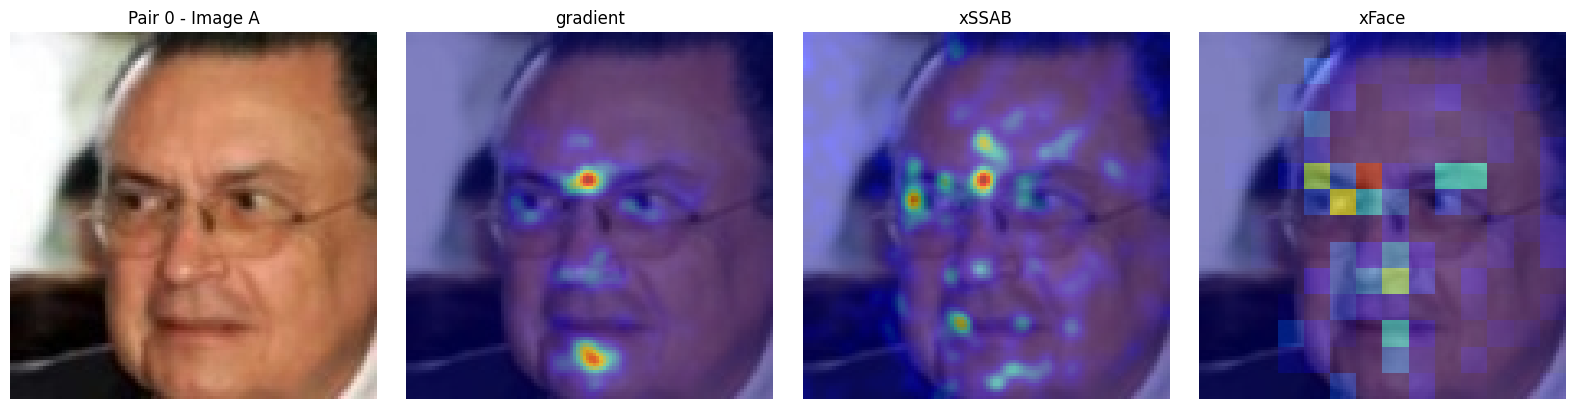

In [11]:
def overlay(img_tensor, sal_np, alpha=0.5):
    raw = tensor_to_uint8(img_tensor)
    hm  = cv2.applyColorMap((sal_np * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm  = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


demo = test_genuine_idx[0]
a, b = load_pair(demo)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(tensor_to_uint8(a)); ax[0].set_title(f'Pair {demo} - Image A')
for k, (name, fn) in enumerate(XAI_METHODS.items(), start=1):
    ax[k].imshow(overlay(a, fn(a, b))); ax[k].set_title(name)
for a_ in ax: a_.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'xai_methods_compare.png'), dpi=120); plt.show()

## Corrected explanation attack (from notebook 04, divergence mode)

Optimised on the **gradient** explanation only, using the softplus-smoothed
model for the differentiable map and the true model for decision stability.

In [12]:
def diff_saliency(img_a, img_b, net, create_graph):
    e_b = net(img_b.unsqueeze(0)).detach()
    acc = 0.0
    n = max(1, SG_SAMPLES)
    for _ in range(n):
        x = img_a
        if SG_SIGMA > 0 and n > 1:
            x = img_a + torch.randn_like(img_a) * SG_SIGMA
        sim  = F.cosine_similarity(net(x.unsqueeze(0)), e_b, dim=1).mean()
        grad = torch.autograd.grad(sim, img_a, create_graph=create_graph)[0]
        acc  = acc + grad.pow(2).mean(dim=0)
    return acc / n


def corr_loss(attacked, original):
    a = attacked.flatten(); b = original.flatten()
    a = a - a.mean(); b = b - b.mean()
    return (a * b).sum() / (a.norm() * b.norm() + 1e-8)


def explanation_attack(img_a_orig, img_b,
                       epsilon=EPSILON, alpha=ALPHA, steps=STEPS_EXPL,
                       lambda_pred=LAMBDA_PRED, lambda_expl=LAMBDA_EXPL,
                       sim_floor=SIM_FLOOR):
    e_b_true = model(img_b.unsqueeze(0)).detach()
    x0 = img_a_orig.clone().detach().requires_grad_(True)
    with torch.enable_grad():
        original = normalize01(diff_saliency(x0, img_b, expl_net, False).detach())

    img_adv = img_a_orig.clone().detach()
    for _ in range(steps):
        img_adv = img_adv.requires_grad_(True)
        sim = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).mean()
        pred_loss = F.relu(sim_floor - sim)
        attacked  = diff_saliency(img_adv, img_b, expl_net, True)
        expl_loss = corr_loss(normalize01(attacked), original)
        loss = lambda_pred * pred_loss + lambda_expl * expl_loss
        grad = torch.autograd.grad(loss, img_adv)[0]
        with torch.no_grad():
            img_adv = img_adv - alpha * grad.sign()
            delta   = torch.clamp(img_adv - img_a_orig, -epsilon, epsilon)
            img_adv = torch.clamp(img_a_orig + delta, -1, 1)
            s = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).item()
            shrink = 0
            while s < sim_floor and shrink < 8:
                delta = delta * 0.5
                img_adv = torch.clamp(img_a_orig + delta, -1, 1)
                s = F.cosine_similarity(model(img_adv.unsqueeze(0)), e_b_true, dim=1).item()
                shrink += 1
    return img_adv.detach()

## Transfer experiment

For each genuine pair we craft **one** adversarial image with the nb04 attack
(which only looks at the `gradient` map), then recompute **all three** maps on
the original vs the adversarial image and record their Pearson correlations.

> **Worked reading of the printout.** Suppose you get `gradient 0.18`,
> `xSSAB 0.34`, `xFace 0.81`. Read it as: the attack shredded its own target
> (0.18), partially carried over to the related gradient×input method (0.34), but
> the occlusion-based reviewer barely noticed (0.81) — so this perturbation is a
> *gradient-map* attack, not a wholesale corruption of the model's reasoning.
> `Decision preserved` should read ≈100%, confirming every one of these is still
> a valid "match": the decision is untouched, only the explanation moved.

In [13]:
from collections import defaultdict

corr_drop = defaultdict(list)     # method -> list of Pearson r (orig vs adv)
preserved = []

for idx in tqdm(test_genuine_idx, desc="Transfer eval"):
    a, b = load_pair(idx)
    adv  = explanation_attack(a, b)
    preserved.append((get_sim(a, b) > THRESHOLD) == (get_sim(adv, b) > THRESHOLD))
    for name, fn in XAI_METHODS.items():
        m0 = fn(a,   b).flatten()
        m1 = fn(adv, b).flatten()
        r, _ = pearsonr(m0, m1)
        corr_drop[name].append(r)

print(f"Decision preserved: {np.mean(preserved):.2%}\n")
print("Method     mean Pearson r (orig vs attacked)   [lower = more disrupted]")
for name in XAI_METHODS:
    print(f"  {name:9s} {np.mean(corr_drop[name]):.4f}")
print("\nThe attack was optimised on 'gradient' only. Compare how far the "
      "gradient-based methods (gradient, xSSAB) drop vs the gradient-free xFace.")

Transfer eval:   0%|          | 0/20 [00:00<?, ?it/s]

Decision preserved: 100.00%

Method     mean Pearson r (orig vs attacked)   [lower = more disrupted]
  gradient  0.2194
  xSSAB     0.5002
  xFace     0.6675

The attack was optimised on 'gradient' only. Compare how far the gradient-based methods (gradient, xSSAB) drop vs the gradient-free xFace.


## Transfer results — bar chart

The same three correlations as bars (with error bars over the test pairs) on a
fixed 0–1 axis so runs are comparable. **How to read it:** a **short** bar = that
explanation was disrupted; a **tall** bar (near 1) = it survived. The bars
usually rise left→right (gradient → xSSAB → xFace) as methods get further from
what the attack optimised. A large gap between the gradient bar and the xFace bar
is the visual headline for *"the attack does not transfer."*

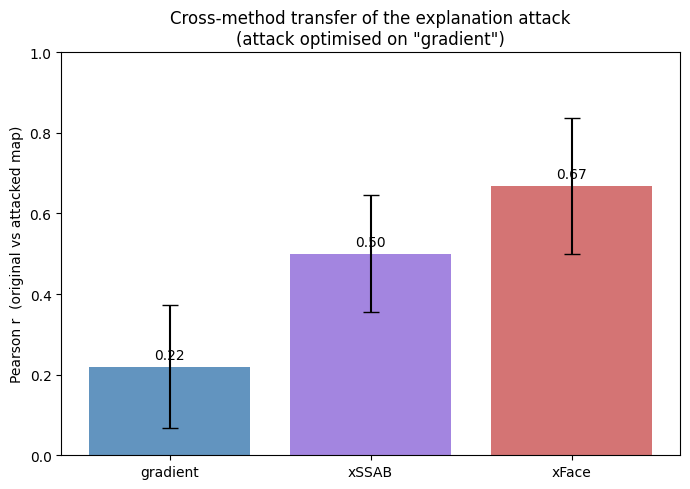

In [14]:
names = list(XAI_METHODS.keys())
means = [np.mean(corr_drop[n]) for n in names]
stds  = [np.std(corr_drop[n])  for n in names]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(names, means, yerr=stds, capsize=6,
              color=['steelblue', 'mediumpurple', 'indianred'], alpha=0.85)
ax.set_ylabel('Pearson r  (original vs attacked map)')
ax.set_title('Cross-method transfer of the explanation attack\n(attack optimised on "gradient")')
ax.set_ylim(0, 1)
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, m + 0.02, f'{m:.2f}', ha='center')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'attack_transfer.png'), dpi=150); plt.show()

## Visualise transfer on one pair (all three methods, before/after)

A 2×3 grid: **top = original maps, bottom = attacked maps**, one column per
method, with the per-method correlation `r` in each bottom title. **How to read
it:** scan the bottom row — a column whose heatmap clearly shifted (low `r`) was
fooled; a column that looks unchanged (high `r`) resisted. This is the
picture-form of the bar chart and the single most convincing figure for a report.

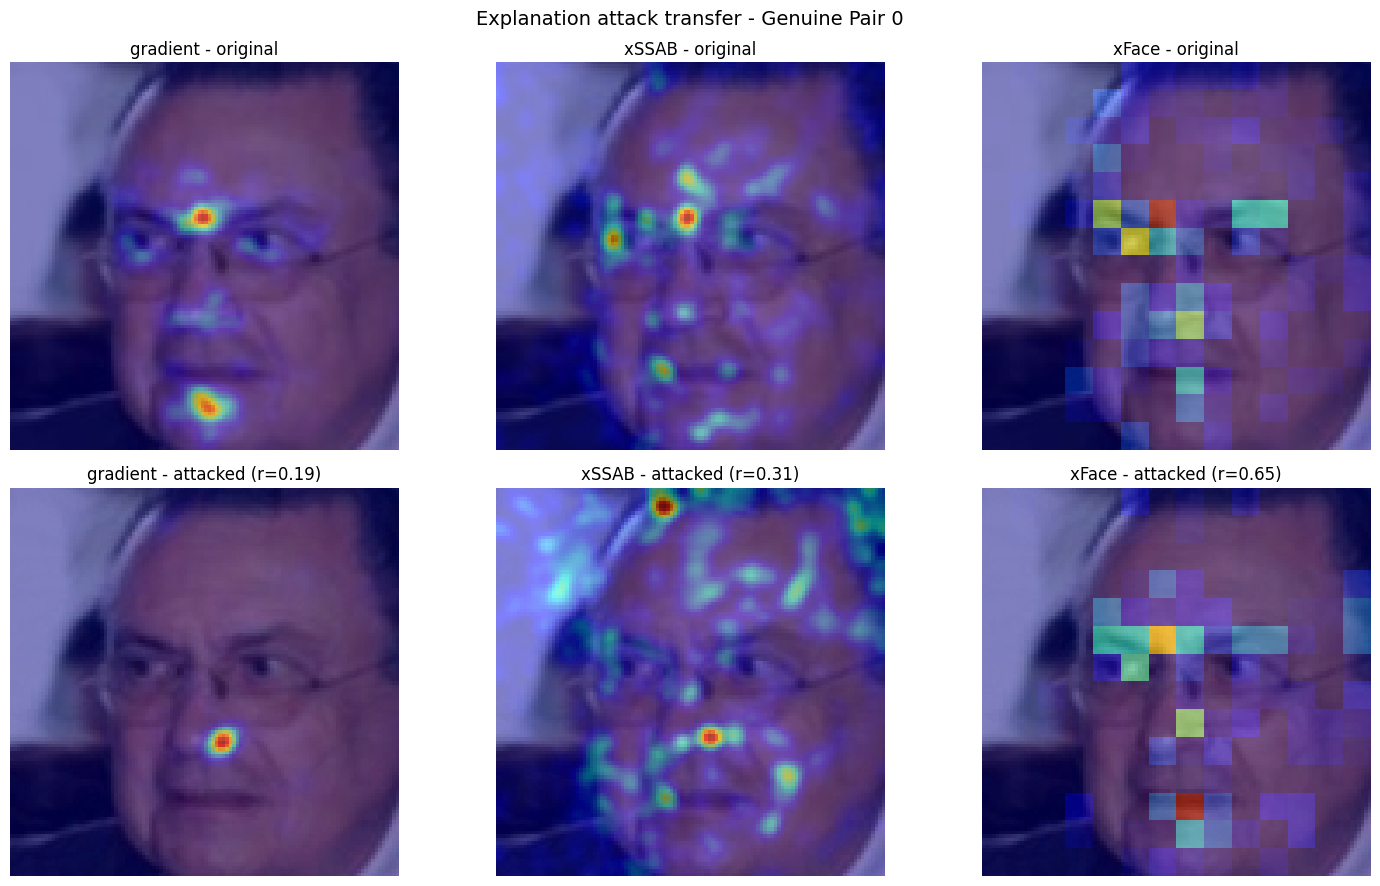

In [15]:
pidx = test_genuine_idx[0]
a, b = load_pair(pidx)
adv  = explanation_attack(a, b)

fig, ax = plt.subplots(2, len(XAI_METHODS), figsize=(5*len(XAI_METHODS), 9))
for k, (name, fn) in enumerate(XAI_METHODS.items()):
    m0, m1 = fn(a, b), fn(adv, b)
    r, _ = pearsonr(m0.flatten(), m1.flatten())
    ax[0, k].imshow(overlay(a,   m0)); ax[0, k].set_title(f'{name} - original')
    ax[1, k].imshow(overlay(adv, m1)); ax[1, k].set_title(f'{name} - attacked (r={r:.2f})')
for a_ in ax.flatten(): a_.axis('off')
fig.suptitle(f'Explanation attack transfer - Genuine Pair {pidx}', fontsize=14)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f'transfer_pair{pidx}.png'), dpi=120); plt.show()

## Notes
* This xSSAB implementation is a simplified, self-contained gradient x input
  decomposition. For the report, swap in the official implementation
  (https://github.com/marcohuber/xSSAB) and/or FAME to strengthen the claim.
* Expected qualitative result: the gradient-based maps (gradient, xSSAB) drop
  more than the gradient-free occlusion map (xFace). Whatever you observe, it is
  the honest robustness picture — a transferable disruption is a stronger attack,
  a non-transferable one shows the current attack is tied to one explainer.

## Results — what this notebook showed

**The attack is real but method-specific: it fools gradient-based explanations,
while the gradient-free one largely resists.**

The perturbation was optimised against the **`gradient`** map only; all three
explanations were then re-measured on 20 genuine pairs (decision preserved:
**100%**):

| Explanation | Correlation after attack | Reading |
|---|---|---|
| gradient (target) | **0.22** | strongly disrupted — its own target |
| xSSAB | **0.50** | partially disrupted — a related gradient-based method |
| xFace (occlusion) | **0.67** | mostly resisted — uses no gradients |

The bar chart is a rising staircase (gradient < xSSAB < xFace): the further a
method is from what the attack targeted, the more it survives. The transfer
figure shows the same story on Pair 0 (gradient r≈0.19, xSSAB r≈0.31, xFace
r≈0.65).

**Takeaway.** The perturbation corrupts the model's *gradient-based* reasoning
display, but a reviewer using an occlusion-based tool (xFace) would still see
roughly the correct region. This is an honest, reportable limitation: the attack
does **not** fully transfer across explanation families.

> Note: the `gradient` correlation here (0.22) is higher than notebook 04's
> (0.06) because this notebook Gaussian-blurs the maps before comparing and uses
> 20 pairs instead of 40. Both still indicate strong disruption — just on a
> slightly different scale.